# EDA — 03. Análisis de Features Numéricas

**Proyecto Final — Uplift Modeling | CAECE**

---

## Objetivo

Análisis exhaustivo de las dos variables numéricas del dataset:
- `recency` — ordinal discreta: meses desde la última compra [1, 12]
- `history` — continua: gasto histórico acumulado en USD

Se cubren: calidad de datos, análisis univariado, bivariado con los tres targets,
correlación entre features, poder predictivo individual (AUC-ROC) y verificación del
balance del RCT.

---

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from IPython.display import display

warnings.filterwarnings("ignore")
try:    plt.style.use("seaborn-v0_8-whitegrid")
except: plt.style.use("seaborn-whitegrid")
sns.set_palette("Set2")
PALETTE = sns.color_palette("Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)

df = pd.read_csv(os.path.join("..", "..", "data", "raw", "hillstrom.csv"))

NUM_FEATURES = ["recency", "history"]
BINARY_TGT   = ["visit", "conversion"]
ALL_TGT      = ["visit", "conversion", "spend"]
SEGMENT      = "segment"
print(f"Dataset: {df.shape[0]:,} × {df.shape[1]}")
print(f"Features numéricas analizadas: {NUM_FEATURES}")

Dataset: 64,000 × 12
Features numéricas analizadas: ['recency', 'history']


## 1. Identificación y Descripción de Variables Numéricas

In [2]:
num_desc = pd.DataFrame([
    {"Variable":"recency", "Naturaleza":"Ordinal discreta",
     "Dominio":"[1, 12] meses", "Semántica":"Tiempo desde última compra",
     "dtype":str(df["recency"].dtype), "N únicos":df["recency"].nunique()},
    {"Variable":"history", "Naturaleza":"Continua",
     "Dominio":"> 0 USD", "Semántica":"Gasto histórico acumulado (USD)",
     "dtype":str(df["history"].dtype), "N únicos":df["history"].nunique()},
])
display(num_desc.style.set_caption("Features numéricas del dataset Hillstrom").hide(axis="index"))

Variable,Naturaleza,Dominio,Semántica,dtype,N únicos
recency,Ordinal discreta,"[1, 12] meses",Tiempo desde última compra,int64,12
history,Continua,> 0 USD,Gasto histórico acumulado (USD),float64,34833


## 2. Auditoría de Calidad

In [3]:
quality = pd.DataFrame({
    "Variable"   : NUM_FEATURES,
    "Nulos"      : [df[c].isnull().sum() for c in NUM_FEATURES],
    "% Nulos"    : [f"{df[c].isnull().mean()*100:.4f}%" for c in NUM_FEATURES],
    "Ceros"      : [int((df[c]==0).sum()) for c in NUM_FEATURES],
    "% Ceros"    : [f"{(df[c]==0).mean()*100:.4f}%" for c in NUM_FEATURES],
    "Min"        : [df[c].min() for c in NUM_FEATURES],
    "Max"        : [df[c].max() for c in NUM_FEATURES],
    "Negativos"  : [int((df[c]<0).sum()) for c in NUM_FEATURES],
})
display(quality.style.set_caption("Auditoría de calidad — features numéricas").hide(axis="index"))
print()
for c in NUM_FEATURES:
    n_null = df[c].isnull().sum()
    n_zero = (df[c] == 0).sum()
    print(f"  {c}: {'sin nulos ✓' if n_null==0 else f'{n_null} nulos'} | {'sin ceros ✓' if n_zero==0 else f'{n_zero} ceros'}")

Variable,Nulos,% Nulos,Ceros,% Ceros,Min,Max,Negativos
recency,0,0.0000%,0,0.0000%,1.000000,12.000000,0
history,0,0.0000%,0,0.0000%,29.990000,3345.930000,0



  recency: sin nulos ✓ | sin ceros ✓
  history: sin nulos ✓ | sin ceros ✓


## 3. Análisis Univariado — `recency`

RECENCY — estadísticos descriptivos
  Rango      : [1, 12] meses
  Media      : 5.7637
  Mediana    : 6
  Desv. std  : 3.5076
  Skewness   : 0.1394
  Kurtosis   : -1.3567
  Moda       : 1


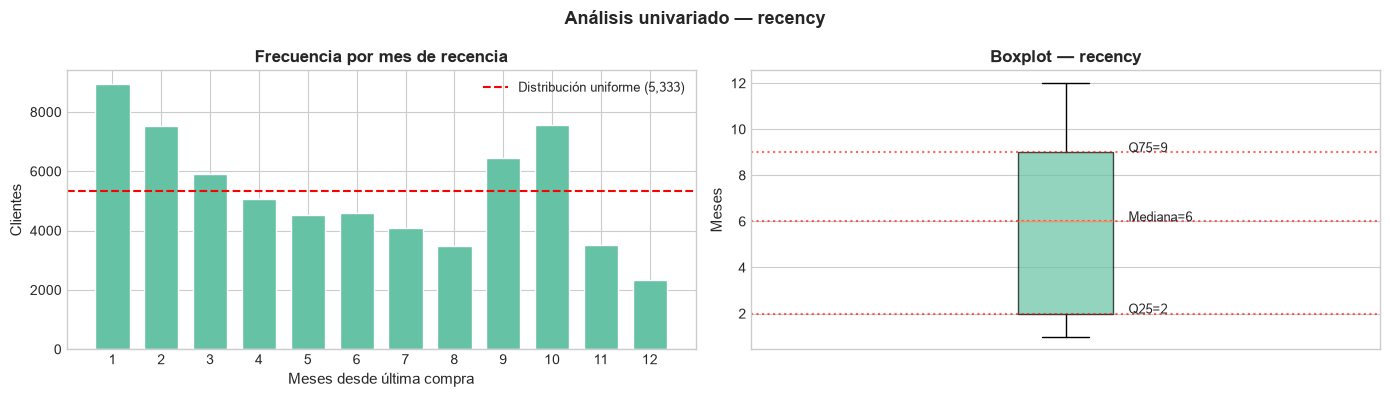

In [4]:
rec = df["recency"]
print("RECENCY — estadísticos descriptivos")
print(f"  Rango      : [{int(rec.min())}, {int(rec.max())}] meses")
print(f"  Media      : {rec.mean():.4f}")
print(f"  Mediana    : {int(rec.median())}")
print(f"  Desv. std  : {rec.std():.4f}")
print(f"  Skewness   : {rec.skew():.4f}")
print(f"  Kurtosis   : {rec.kurtosis():.4f}")
print(f"  Moda       : {int(rec.mode()[0])}")

# Bar chart de frecuencias (discreta)
vc = rec.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(vc.index, vc.values, color=PALETTE[0], edgecolor="white", width=0.7)
axes[0].axhline(len(df)/12, color="red", ls="--", lw=1.5, label=f"Distribución uniforme ({len(df)//12:,})")
axes[0].set_xlabel("Meses desde última compra", fontsize=11)
axes[0].set_ylabel("Clientes", fontsize=11)
axes[0].set_title("Frecuencia por mes de recencia", fontsize=12, fontweight="bold")
axes[0].set_xticks(range(1, 13))
axes[0].legend(fontsize=9)

# Boxplot
axes[1].boxplot(rec.values, vert=True, patch_artist=True,
                boxprops={"facecolor":PALETTE[0], "alpha":0.7})
axes[1].set_ylabel("Meses", fontsize=11)
axes[1].set_title("Boxplot — recency", fontsize=12, fontweight="bold")
axes[1].set_xticks([])
for pct_val, pct_lbl in [(25,"Q25"),(50,"Mediana"),(75,"Q75")]:
    pval = np.percentile(rec, pct_val)
    axes[1].axhline(pval, color="red", ls=":", alpha=0.6)
    axes[1].text(1.1, pval, f"{pct_lbl}={pval:.0f}", fontsize=9)

plt.suptitle("Análisis univariado — recency", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [5]:
# Tabla de frecuencias de recency
rec_table = (df["recency"].value_counts().sort_index()
             .rename_axis("Meses").reset_index(name="N"))
rec_table["% total"]     = (rec_table["N"] / len(df) * 100).round(2)
rec_table["% acumulado"] = rec_table["% total"].cumsum().round(2)
rec_table["vs uniforme"] = (rec_table["% total"] - 100/12).round(2)

display(rec_table.style
    .format({"% total":"{:.2f}%","% acumulado":"{:.2f}%","vs uniforme":"{:+.2f}%"})
    .set_caption("Distribución de recency por mes")
    .hide(axis="index"))

# Test de uniformidad (chi-square)
from scipy.stats import chisquare
obs = rec_table["N"].values
exp = [len(df)/12] * 12
chi2_stat, chi2_p = chisquare(obs, f_exp=exp)
print(f"\nTest χ² de uniformidad de recency:")
print(f"  χ² = {chi2_stat:.4f},  p = {chi2_p:.8f}")
print(f"  → {'NO uniforme' if chi2_p < 0.05 else 'Uniforme'} (α=0.05)")

Meses,N,% total,% acumulado,vs uniforme
1,8952,13.99%,13.99%,+5.66%
2,7537,11.78%,25.77%,+3.45%
3,5904,9.22%,34.99%,+0.89%
4,5077,7.93%,42.92%,-0.40%
5,4510,7.05%,49.97%,-1.28%
6,4605,7.20%,57.17%,-1.13%
7,4078,6.37%,63.54%,-1.96%
8,3495,5.46%,69.00%,-2.87%
9,6441,10.06%,79.06%,+1.73%
10,7565,11.82%,90.88%,+3.49%



Test χ² de uniformidad de recency:
  χ² = 8075.1871,  p = 0.00000000
  → NO uniforme (α=0.05)


## 4. Análisis Univariado — `history`

In [6]:
hist_var = df["history"]
print("HISTORY — estadísticos descriptivos")
print(f"  Rango         : [${hist_var.min():.2f}, ${hist_var.max():,.2f}]")
print(f"  Q25           : ${hist_var.quantile(0.25):.2f}")
print(f"  Mediana       : ${hist_var.median():.2f}")
print(f"  Media         : ${hist_var.mean():.2f}")
print(f"  Q75           : ${hist_var.quantile(0.75):.2f}")
print(f"  Desv. std     : ${hist_var.std():.2f}")
print(f"  Skewness      : {hist_var.skew():.4f}")
print(f"  Kurtosis      : {hist_var.kurtosis():.4f}")

log_hist = np.log1p(hist_var)
_, pval_hist = stats.normaltest(log_hist)
print(f"\n  Normaltest en log₁₊(history): p = {pval_hist:.6f}")

HISTORY — estadísticos descriptivos
  Rango         : [$29.99, $3,345.93]
  Q25           : $64.66
  Mediana       : $158.11
  Media         : $242.09
  Q75           : $325.66
  Desv. std     : $256.16
  Skewness      : 2.4238
  Kurtosis      : 9.3467

  Normaltest en log₁₊(history): p = 0.000000


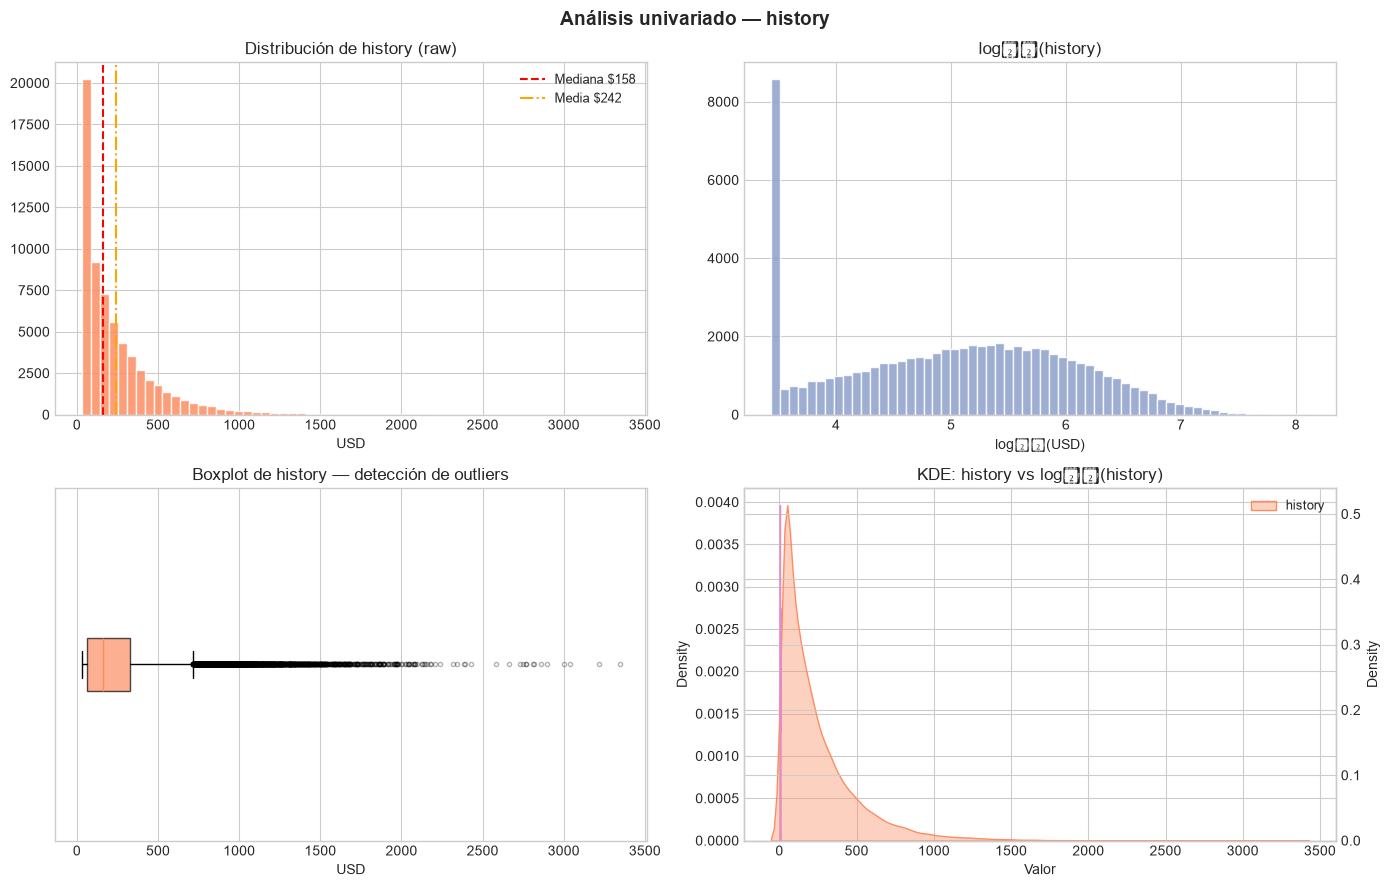

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Histograma raw
axes[0,0].hist(hist_var.values, bins=60, color=PALETTE[1], edgecolor="white", alpha=0.85)
axes[0,0].axvline(hist_var.median(), color="red",    ls="--", lw=1.5, label=f"Mediana ${hist_var.median():.0f}")
axes[0,0].axvline(hist_var.mean(),   color="orange", ls="-.", lw=1.5, label=f"Media ${hist_var.mean():.0f}")
axes[0,0].set_title("Distribución de history (raw)", fontsize=12)
axes[0,0].set_xlabel("USD")
axes[0,0].legend(fontsize=9)

# 2) log1p transform
axes[0,1].hist(np.log1p(hist_var).values, bins=60, color=PALETTE[2], edgecolor="white", alpha=0.85)
axes[0,1].set_title("log₁₊(history)", fontsize=12)
axes[0,1].set_xlabel("log₁₊(USD)")

# 3) Boxplot con outliers
axes[1,0].boxplot(hist_var.values, vert=False, patch_artist=True,
                  boxprops={"facecolor":PALETTE[1],"alpha":0.7},
                  flierprops={"marker":"o","markersize":3,"alpha":0.3})
axes[1,0].set_title("Boxplot de history — detección de outliers", fontsize=12)
axes[1,0].set_xlabel("USD")
axes[1,0].set_yticks([])

# 4) KDE comparativo raw vs log
sns.kdeplot(hist_var.values, ax=axes[1,1], label="history", color=PALETTE[1], fill=True, alpha=0.4)
ax2 = axes[1,1].twinx()
sns.kdeplot(np.log1p(hist_var).values, ax=ax2, label="log(history)", color=PALETTE[3], fill=True, alpha=0.3)
axes[1,1].set_title("KDE: history vs log₁₊(history)", fontsize=12)
axes[1,1].set_xlabel("Valor")
axes[1,1].legend(loc="upper right", fontsize=9)

plt.suptitle("Análisis univariado — history", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [8]:
# Detección de outliers — método IQR y Z-score
Q1, Q3 = hist_var.quantile(0.25), hist_var.quantile(0.75)
IQR    = Q3 - Q1
lo, hi = Q1 - 1.5*IQR, Q3 + 1.5*IQR

n_iqr_out = ((hist_var < lo) | (hist_var > hi)).sum()
zscores   = np.abs(stats.zscore(hist_var))
n_z3_out  = (zscores > 3).sum()

print("OUTLIERS — history")
print(f"  IQR method [Q1-1.5·IQR, Q3+1.5·IQR] = [{lo:.2f}, {hi:.2f}]")
print(f"    Outliers: {n_iqr_out:,}  ({n_iqr_out/len(df)*100:.2f}%)")
print(f"  Z-score > 3:")
print(f"    Outliers: {n_z3_out:,}  ({n_z3_out/len(df)*100:.2f}%)")
print()
print("Top 5 valores más altos de history:")
top5 = df.nlargest(5, "history")[["history", "history_segment", "segment", "visit", "conversion", "spend"]]
display(top5.style.hide(axis="index"))

OUTLIERS — history
  IQR method [Q1-1.5·IQR, Q3+1.5·IQR] = [-326.84, 717.15]
    Outliers: 3,593  (5.61%)
  Z-score > 3:
    Outliers: 1,271  (1.99%)

Top 5 valores más altos de history:


history,history_segment,segment,visit,conversion,spend
3345.930000,"7) $1,000 +",No E-Mail,0,0,0.000000
3215.970000,"7) $1,000 +",Mens E-Mail,1,0,0.000000
3040.200000,"7) $1,000 +",Womens E-Mail,0,0,0.000000
3003.480000,"7) $1,000 +",No E-Mail,0,0,0.000000
2895.110000,"7) $1,000 +",Mens E-Mail,0,0,0.000000


## 5. Análisis Bivariado — Features Numéricas × Targets Binarios

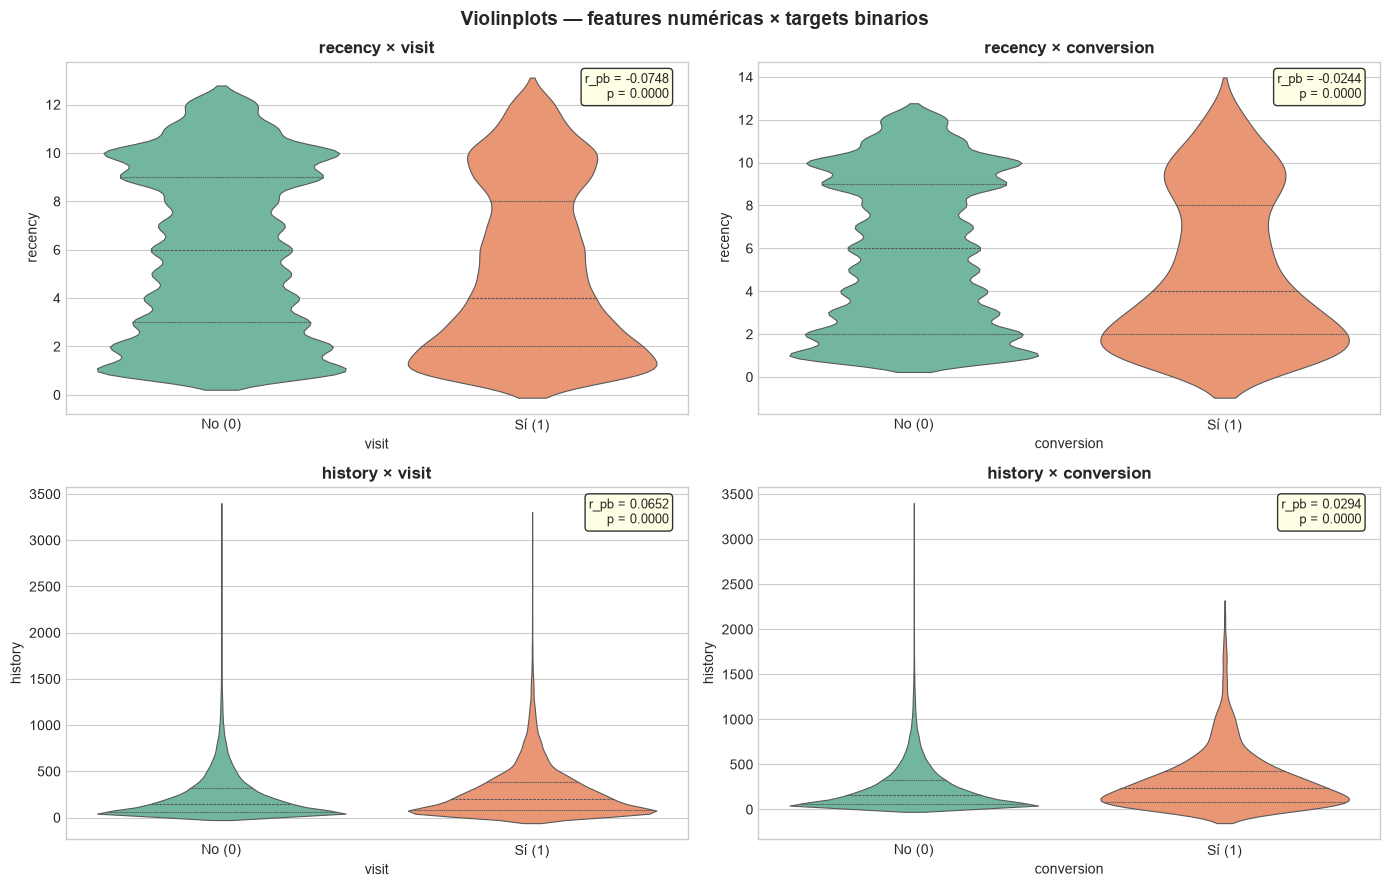

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for row, feat in enumerate(["recency", "history"]):
    for col, tgt in enumerate(["visit", "conversion"]):
        ax = axes[row, col]
        sns.violinplot(data=df, x=tgt, y=feat, palette="Set2",
                       ax=ax, inner="quartile", linewidth=0.8)
        ax.set_title(f"{feat} × {tgt}", fontsize=12, fontweight="bold")
        ax.set_xlabel(tgt)
        ax.set_ylabel(feat)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["No (0)", "Sí (1)"])

        # Point-biserial correlation
        r, pval = stats.pointbiserialr(df[tgt], df[feat])
        ax.text(0.97, 0.97, f"r_pb = {r:.4f}\np = {pval:.4f}",
                transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox=dict(boxstyle="round", facecolor="lightyellow", alpha=0.8))

plt.suptitle("Violinplots — features numéricas × targets binarios",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

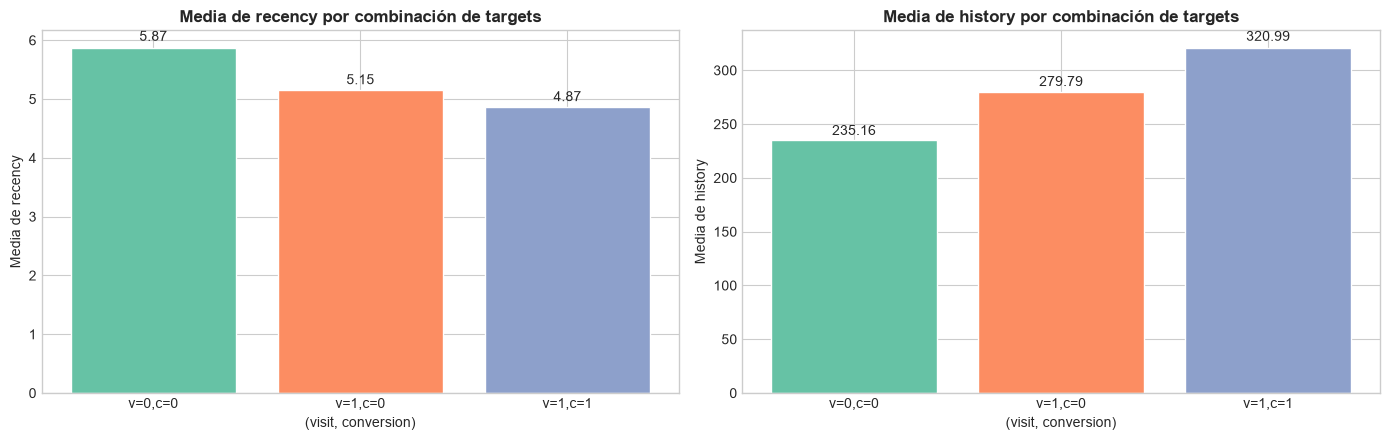

In [10]:
# Boxplots adicionales para comparar medias
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, feat in zip(axes, ["recency", "history"]):
    means = df.groupby(["visit","conversion"])[feat].mean().reset_index()
    # Group label
    means["grupo"] = means.apply(
        lambda r: f"v={int(r.visit)},c={int(r.conversion)}", axis=1)
    ax.bar(means["grupo"], means[feat], color=PALETTE[:len(means)], edgecolor="white")
    for i, (_, row_data) in enumerate(means.iterrows()):
        ax.text(i, row_data[feat] + row_data[feat]*0.02,
                f"{row_data[feat]:.2f}", ha="center", fontsize=10)
    ax.set_title(f"Media de {feat} por combinación de targets", fontsize=12, fontweight="bold")
    ax.set_ylabel(f"Media de {feat}")
    ax.set_xlabel("(visit, conversion)")
plt.tight_layout()
plt.show()

## 6. Análisis Bivariado — Features Numéricas × Spend

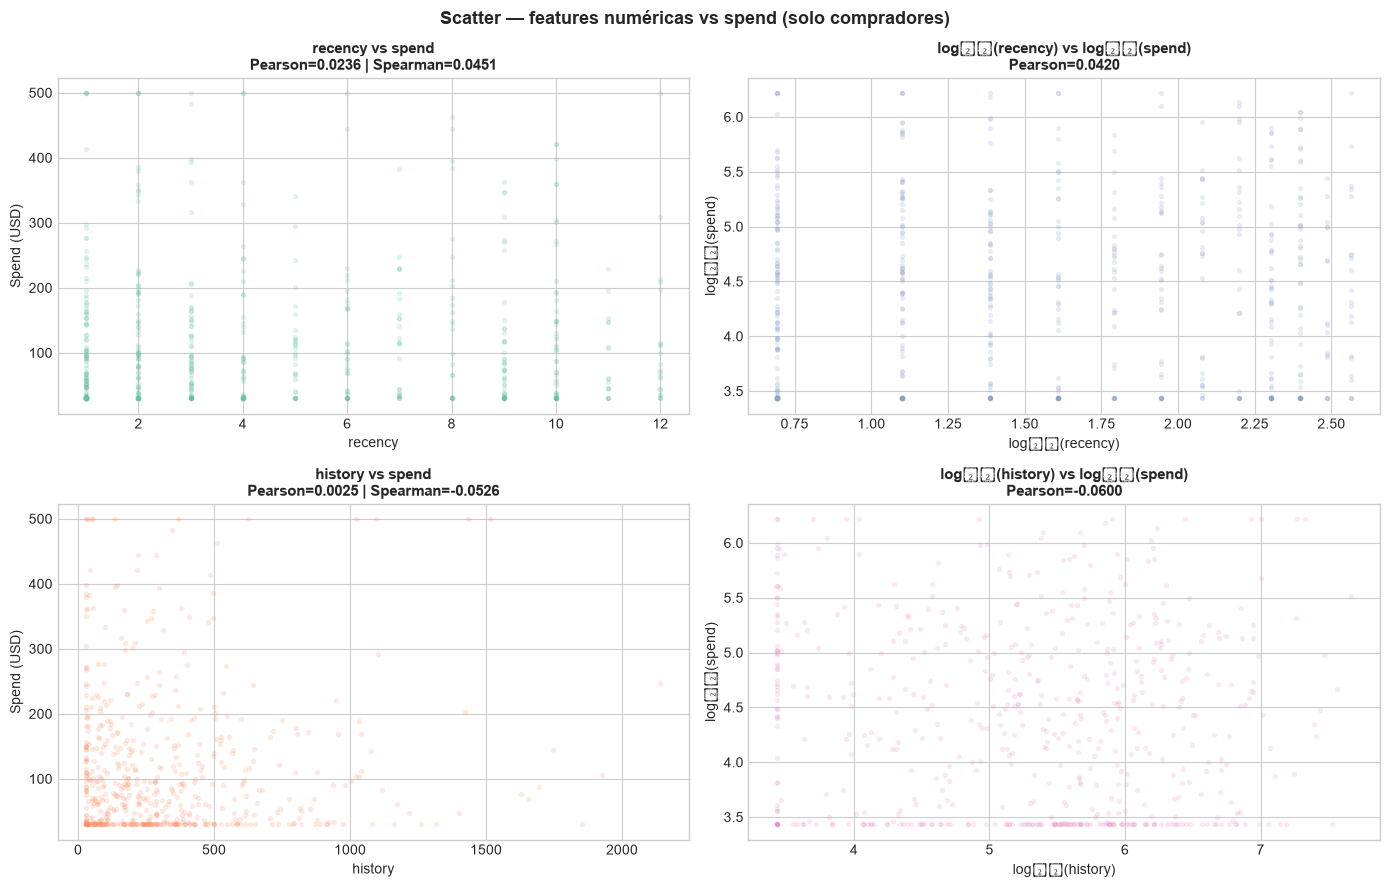

In [11]:
df_nz = df[df["spend"] > 0].copy()
df_nz["log_spend"] = np.log1p(df_nz["spend"])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for row, feat in enumerate(["recency", "history"]):
    # Scatter raw
    axes[row,0].scatter(df_nz[feat], df_nz["spend"],
                        alpha=0.15, s=8, color=PALETTE[row])
    r_p = df_nz[[feat,"spend"]].corr().iloc[0,1]
    r_s = df_nz[[feat,"spend"]].corr(method="spearman").iloc[0,1]
    axes[row,0].set_title(f"{feat} vs spend\nPearson={r_p:.4f} | Spearman={r_s:.4f}",
                          fontsize=11, fontweight="bold")
    axes[row,0].set_xlabel(feat)
    axes[row,0].set_ylabel("Spend (USD)")

    # Scatter log-log
    axes[row,1].scatter(np.log1p(df_nz[feat]), df_nz["log_spend"],
                        alpha=0.15, s=8, color=PALETTE[row+2])
    r_p_log = np.corrcoef(np.log1p(df_nz[feat]), df_nz["log_spend"])[0,1]
    axes[row,1].set_title(f"log₁₊({feat}) vs log₁₊(spend)\nPearson={r_p_log:.4f}",
                          fontsize=11, fontweight="bold")
    axes[row,1].set_xlabel(f"log₁₊({feat})")
    axes[row,1].set_ylabel("log₁₊(spend)")

plt.suptitle("Scatter — features numéricas vs spend (solo compradores)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Correlación entre Features Numéricas

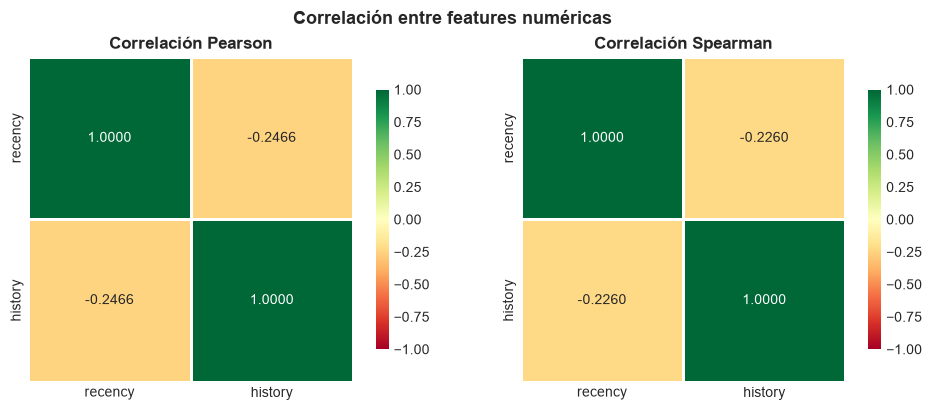

Pearson  recency ↔ history : -0.2466
Spearman recency ↔ history : -0.2260

→ Correlación baja entre features numéricas — no hay multicolinealidad severa.


In [12]:
corr_pearson  = df[NUM_FEATURES].corr(method="pearson")
corr_spearman = df[NUM_FEATURES].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, corr, method in zip(axes, [corr_pearson, corr_spearman], ["Pearson","Spearman"]):
    sns.heatmap(corr, annot=True, fmt=".4f", cmap="RdYlGn",
                center=0, vmin=-1, vmax=1, ax=ax, square=True,
                linewidths=1, cbar_kws={"shrink":0.8})
    ax.set_title(f"Correlación {method}", fontsize=12, fontweight="bold")
plt.suptitle("Correlación entre features numéricas", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

r_p = corr_pearson.loc["recency","history"]
r_s = corr_spearman.loc["recency","history"]
print(f"Pearson  recency ↔ history : {r_p:.4f}")
print(f"Spearman recency ↔ history : {r_s:.4f}")
print()
note = "baja" if abs(r_p) < 0.3 else ("moderada" if abs(r_p) < 0.6 else "alta")
print(f"→ Correlación {note} entre features numéricas — no hay multicolinealidad severa.")

## 8. Balance del RCT — Features Numéricas por Grupo de Tratamiento


  Kruskal-Wallis recency: H=0.4611, p=0.794099  → Balanceado ✓
  Kruskal-Wallis history: H=0.8102, p=0.666902  → Balanceado ✓


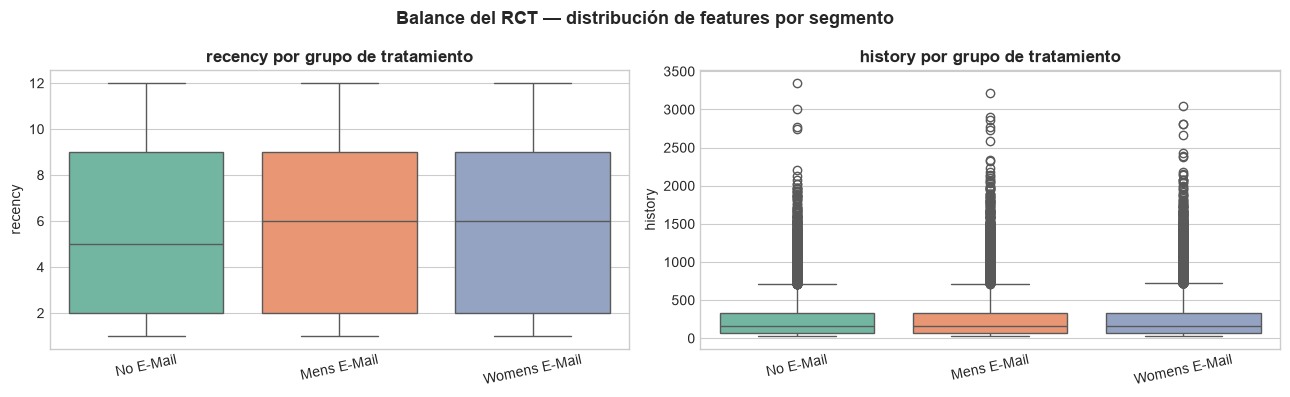

In [13]:
# En un RCT bien aleatorizado, la distribución de features debe ser similar en los 3 grupos.
balance = df.groupby("segment")[NUM_FEATURES].agg(["mean","std","median"]).round(4)
display(balance.style.set_caption("Features numéricas por grupo de tratamiento — verificación de balance del RCT"))

print()
ORDER_SEG = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]
for feat in NUM_FEATURES:
    groups = [df.loc[df["segment"]==s, feat].values for s in ORDER_SEG]
    stat, pval = stats.kruskal(*groups)
    print(f"  Kruskal-Wallis {feat}: H={stat:.4f}, p={pval:.6f}  → {'NO balanceado' if pval<0.05 else 'Balanceado ✓'}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, feat in zip(axes, NUM_FEATURES):
    sns.boxplot(data=df, x="segment", y=feat, order=ORDER_SEG, palette="Set2", ax=ax)
    ax.set_title(f"{feat} por grupo de tratamiento", fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=12)
plt.suptitle("Balance del RCT — distribución de features por segmento",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 9. Poder Predictivo Individual — AUC-ROC por Feature

In [14]:
def feature_auc(feat_vals, y_binary):
    try:
        auc = roc_auc_score(y_binary, feat_vals)
        return max(auc, 1 - auc)
    except:
        return np.nan

results_auc = []
for feat in NUM_FEATURES:
    for tgt in BINARY_TGT:
        auc = feature_auc(df[feat].values, df[tgt].values)
        results_auc.append({"Feature":feat, "Target":tgt, "AUC-ROC":auc})

# Para spend: correlaciones
for feat in NUM_FEATURES:
    r_p = abs(df[[feat,"spend"]].corr().iloc[0,1])
    r_s = abs(df[[feat,"spend"]].corr(method="spearman").iloc[0,1])
    results_auc.append({"Feature":feat, "Target":"spend (|Pearson|)",  "AUC-ROC":r_p})
    results_auc.append({"Feature":feat, "Target":"spend (|Spearman|)", "AUC-ROC":r_s})

auc_df   = pd.DataFrame(results_auc)
auc_pivot = auc_df.pivot(index="Feature", columns="Target", values="AUC-ROC")

display(auc_pivot.style
    .format("{:.4f}")
    .background_gradient(cmap="RdYlGn", axis=None, vmin=0.5, vmax=0.75)
    .set_caption("Poder predictivo individual — AUC-ROC (binario) y |correlación| (continuo)")
)
print()
print("Interpretación AUC-ROC:")
print("  0.50 = sin poder predictivo (igual que azar)")
print("  0.55 = débil  |  0.60 = moderado  |  0.70+ = bueno  |  0.80+ = muy bueno")

Target,conversion,spend (|Pearson|),spend (|Spearman|),visit
Feature,,,,
history,0.5775,0.0217,0.0254,0.5572
recency,0.5764,0.0163,0.0251,0.5614



Interpretación AUC-ROC:
  0.50 = sin poder predictivo (igual que azar)
  0.55 = débil  |  0.60 = moderado  |  0.70+ = bueno  |  0.80+ = muy bueno


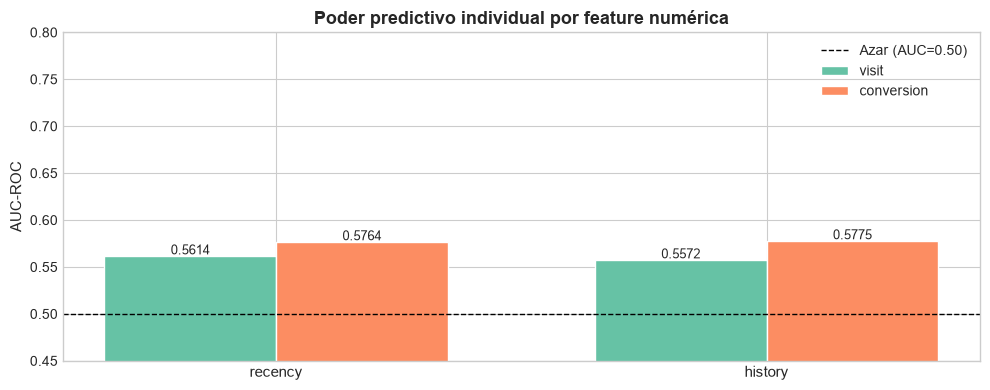

In [15]:
# Visualización del poder predictivo
fig, ax = plt.subplots(figsize=(10, 4))
auc_long = auc_df[auc_df["Target"].isin(BINARY_TGT)].copy()
x = np.arange(len(NUM_FEATURES))
width = 0.35
for i, tgt in enumerate(BINARY_TGT):
    vals = [auc_long.loc[(auc_long["Feature"]==f)&(auc_long["Target"]==tgt), "AUC-ROC"].values[0]
            for f in NUM_FEATURES]
    bars = ax.bar(x + i*width - width/2, vals, width, label=tgt, color=PALETTE[i], edgecolor="white")
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
                f"{v:.4f}", ha="center", fontsize=9)
ax.axhline(0.5, color="black", ls="--", lw=1, label="Azar (AUC=0.50)")
ax.set_xticks(x)
ax.set_xticklabels(NUM_FEATURES, fontsize=11)
ax.set_ylabel("AUC-ROC", fontsize=11)
ax.set_ylim(0.45, 0.80)
ax.set_title("Poder predictivo individual por feature numérica", fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

In [16]:
# Complemento: F1 con umbral óptimo via Logistic Regression univariada
from sklearn.metrics import f1_score
from sklearn.model_selection import cross_val_predict

f1_results = []
for feat in NUM_FEATURES:
    X = df[[feat]].values
    for tgt in BINARY_TGT:
        y = df[tgt].values
        scaler = StandardScaler()
        X_sc   = scaler.fit_transform(X)
        lr     = LogisticRegression(class_weight="balanced", random_state=42, max_iter=500)
        y_pred = cross_val_predict(lr, X_sc, y, cv=5, method="predict")
        f1     = f1_score(y, y_pred)
        f1_results.append({"Feature":feat, "Target":tgt, "F1 (LR, balanced, cv=5)":f1})

f1_df = pd.DataFrame(f1_results).pivot(index="Feature", columns="Target", values="F1 (LR, balanced, cv=5)")
display(f1_df.style
    .format("{:.4f}")
    .background_gradient(cmap="RdYlGn", axis=None)
    .set_caption("F1-score — Logistic Regression univariada con class_weight=balanced (cv=5)")
)
print()
print("Nota: F1 con class_weight=balanced compensa el desbalance de clases.")

Target,conversion,visit
Feature,,
history,0.0247,0.2509
recency,0.0218,0.2634



Nota: F1 con class_weight=balanced compensa el desbalance de clases.


## 10. Feature Selection — Boruta (Features Numéricas)

In [17]:
try:
    from boruta import BorutaPy
    from sklearn.ensemble import RandomForestClassifier
    HAS_BORUTA = True
except ImportError:
    HAS_BORUTA = False
    print("Instalar Boruta: poetry add Boruta")

if HAS_BORUTA:
    X_num = df[NUM_FEATURES].values
    boruta_results = {}

    for tgt in BINARY_TGT:
        y = df[tgt].values
        rf = RandomForestClassifier(n_estimators=150, max_depth=6,
                                    random_state=42, n_jobs=-1, class_weight="balanced")
        boruta_sel = BorutaPy(rf, n_estimators="auto", verbose=0,
                              random_state=42, max_iter=100, alpha=0.05)
        boruta_sel.fit(X_num, y)
        boruta_results[tgt] = {
            "support"  : boruta_sel.support_,
            "tentative": boruta_sel.support_weak_,
            "ranking"  : boruta_sel.ranking_,
        }

    print("BORUTA — Features Numéricas")
    print(f"{'─'*50}")
    for tgt, res in boruta_results.items():
        print(f"\n  Target: {tgt}")
        for feat, sup, tent, rank in zip(NUM_FEATURES, res["support"], res["tentative"], res["ranking"]):
            estado = "✓ Confirmada" if sup else ("○ Tentativa" if tent else "✗ Rechazada")
            print(f"    {feat:<12} | Ranking {rank} | {estado}")

BORUTA — Features Numéricas
──────────────────────────────────────────────────

  Target: visit
    recency      | Ranking 1 | ✓ Confirmada
    history      | Ranking 1 | ✓ Confirmada

  Target: conversion
    recency      | Ranking 1 | ✓ Confirmada
    history      | Ranking 1 | ✓ Confirmada


## 11. Síntesis

In [18]:
print("═"*65)
print("  SÍNTESIS — FEATURES NUMÉRICAS")
print("═"*65)
for feat in NUM_FEATURES:
    print(f"\n  {feat.upper()}")
    print(f"    Rango      : [{df[feat].min():.2f}, {df[feat].max():.2f}]")
    print(f"    Skewness   : {df[feat].skew():.4f}")
    print(f"    AUC-ROC vs visit      : {feature_auc(df[feat].values, df['visit'].values):.4f}")
    print(f"    AUC-ROC vs conversion : {feature_auc(df[feat].values, df['conversion'].values):.4f}")
    print(f"    |Pearson| vs spend    : {abs(df[[feat,'spend']].corr().iloc[0,1]):.4f}")
print()
print("═"*65)
print("Interpretación:")
print("  → history muestra mayor poder predictivo individual que recency.")
print("  → Ambas features pasan el balance check del RCT (distribución similar en los 3 grupos).")
print("  → La correlación entre recency e history es baja — no hay multicolinealidad severa.")
print("═"*65)

═════════════════════════════════════════════════════════════════
  SÍNTESIS — FEATURES NUMÉRICAS
═════════════════════════════════════════════════════════════════

  RECENCY
    Rango      : [1.00, 12.00]
    Skewness   : 0.1394
    AUC-ROC vs visit      : 0.5614
    AUC-ROC vs conversion : 0.5764
    |Pearson| vs spend    : 0.0163

  HISTORY
    Rango      : [29.99, 3345.93]
    Skewness   : 2.4238
    AUC-ROC vs visit      : 0.5572
    AUC-ROC vs conversion : 0.5775
    |Pearson| vs spend    : 0.0217

═════════════════════════════════════════════════════════════════
Interpretación:
  → history muestra mayor poder predictivo individual que recency.
  → Ambas features pasan el balance check del RCT (distribución similar en los 3 grupos).
  → La correlación entre recency e history es baja — no hay multicolinealidad severa.
═════════════════════════════════════════════════════════════════


---
## Conclusión

- **`recency`**: distribución discreta, levemente no-uniforme (más clientes con recencia reciente). Poder predictivo individual bajo pero significativo.
- **`history`**: distribución continua fuertemente asimétrica a la derecha (skewness alto). Requiere transformación logarítmica para modelos lineales. Mayor poder predictivo que recency.
- **Balance del RCT**: ambas features muestran distribuciones similares en los tres grupos de tratamiento, confirmando la validez de la aleatorización.
- **Para los meta-learners**: considerar `log1p(history)` como feature transformada.

**Siguiente:** `04_categorical_features.ipynb`